# Chapter 30 — Convexity, Timing, and Quanto Adjustments

Every worked example in the chapter, recomputed, and both of its figures regenerated. Each number is
printed beside the value the chapter prints, so a figure that drifted is visible rather than merely
wrong.

| Section | What it reproduces | Example |
|---|---|---|
| 1 | A payment deferred by one quarter, and what the linearization costs | 30.1 |
| 2 | Futures against forwards: Ho–Lee, Hull–White, Figure 30.1 | — |
| 3 | In-arrears convexity, exact against first order | 30.2 |
| 4 | The CMS adjustment, checked against the full annuity-measure integral; Figure 30.2 | 30.3 |
| 5 | A CMS spread coupon: why the legs do not cancel | 30.4 |
| 6 | The quanto drift, and the Nikkei forward | — |

Every adjustment in the chapter is one calculation: the covariance between the payoff and the density
that takes the measure the variable is unbiased under to the measure the contract needs. The sections
below are that calculation done six times.

Everything is deterministic. Two figures are computed by quadrature rather than by a closed form, and
both say so.

NumPy, SciPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, log, sqrt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.stats import norm

N, phi = norm.cdf, norm.pdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """Print a computed value beside the one the chapter prints. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.6f   book %11.6f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def lognormal_expect(f, mean, total_vol):
    """E[f(X)] for X lognormal with the given mean and sigma*sqrt(T), by quadrature."""
    g = lambda z: f(mean * exp(total_vol * z - 0.5 * total_vol ** 2)) * phi(z)
    return quad(g, -12, 12, limit=200)[0]

## 1. A payment deferred by one quarter — Example 30.1

Deferring a payment from $T^*$ to $T$ discounts it over a period whose rate is not known today. When
the payoff is large exactly when that rate is high ($\rho > 0$), the large payoffs are the ones
discounted most, and the deferred claim is worth less. The adjustment scales with $\tau T^*$, the
deferral length times the time to observation, so the plot is a fan: almost nothing for a payoff
observed soon, steadily more as observation recedes.

Half a basis point looks like rounding, and on one trade it is. On a \$5 billion note program it is
\$275,000 a year, and it is always in the same direction.

The exponential form (30.8) is exact when $V$ and the discount factor are jointly lognormal; with the
*rate* lognormal instead, the exact answer needs one integral. Doing it measures what the market's
form costs: four hundredths of a basis point here.

exponent                                          -0.001386   book   -0.001386   ok
adjusted rate, %                                   3.994459   book    3.994500   ok
timing adjustment, bp                             -0.554071   book   -0.550000   ok
on a $5bn program, $ a year                    277035.673492   book 275000.000000   ok

exact, rate lognormal (quadrature), %              3.994072   book    3.994100   ok
the market's form overstates E^T[V] by 0.04 bp


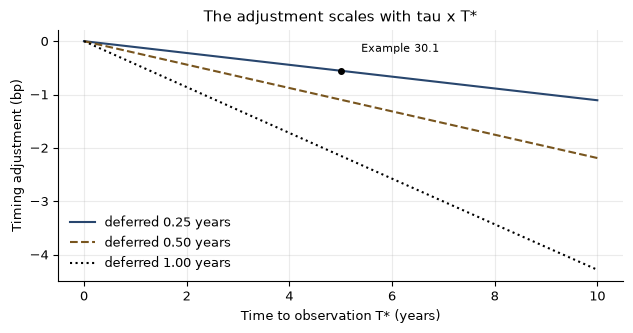

In [2]:
V0, SIG_V, Y0, SIG_Y, RHO, T_STAR, TAU = 0.04, 0.20, 0.04, 0.20, 0.7, 5.0, 0.25


def timing_exp(V0, sV, y0, sy, rho, Ts, tau):
    """Eq. (30.8), the exponential form the market quotes."""
    return V0 * exp(-rho * sV * sy * y0 * tau * Ts / (1 + y0 * tau))


x = -RHO * SIG_V * SIG_Y * Y0 * TAU * T_STAR / (1 + Y0 * TAU)
adj = timing_exp(V0, SIG_V, Y0, SIG_Y, RHO, T_STAR, TAU)
show("exponent", x, -0.001386, 5e-7)
show("adjusted rate, %", 100 * adj, 3.9945, 5e-5)
show("timing adjustment, bp", 1e4 * (adj - V0), -0.55, 5e-3)
show("on a $5bn program, $ a year", 5e9 * (V0 - adj), 275000, 5000)
print()


def timing_exact(V0, sV, y0, sy, rho, Ts, tau):
    """E^T[V] = E[V D] / D0 with the rate y lognormal, eq. (30.6). Conditioning on the
    rate's normal driver z, E[V | z] shifts z by rho sV sqrt(Ts), leaving one integral.
    The rate's median m is set so that E[1/(1 + y tau)] = 1/(1 + y0 tau) exactly."""
    s, v = sy * sqrt(Ts), sV * sqrt(Ts)
    D0 = 1 / (1 + y0 * tau)
    ED = lambda m, shift: quad(lambda z: phi(z) / (1 + m * exp(s * (z + shift)) * tau), -12, 12)[0]
    m = brentq(lambda m: ED(m, 0.0) - D0, 0.2 * y0, 2 * y0)
    return V0 * ED(m, rho * v) / D0


exact = timing_exact(V0, SIG_V, Y0, SIG_Y, RHO, T_STAR, TAU)
show("exact, rate lognormal (quadrature), %", 100 * exact, 3.9941, 5e-5)
print("the market's form overstates E^T[V] by %.2f bp" % (1e4 * (adj - exact)))

Ts = np.linspace(0, 10, 101)
fig, ax = plt.subplots()
for tau, ls, col in ((0.25, "-", BLUE), (0.5, "--", AMBER), (1.0, ":", "black")):
    ax.plot(Ts, [1e4 * (timing_exp(V0, SIG_V, Y0, SIG_Y, RHO, t, tau) - V0) for t in Ts], ls,
            color=col, lw=1.5, label="deferred %.2f years" % tau)
ax.plot([T_STAR], [1e4 * (adj - V0)], "o", color="black", ms=4)
ax.annotate("Example 30.1", xy=(T_STAR, 1e4 * (adj - V0)), xytext=(5.4, -0.2), fontsize=8)
ax.set_xlabel("Time to observation T* (years)"); ax.set_ylabel("Timing adjustment (bp)")
ax.set_title("The adjustment scales with tau x T*")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

## 2. Futures against forwards — Figure 30.1

Daily margining makes the money market account the futures contract's numeraire, so the futures rate
is an expectation under $Q$ and the forward rate one under $Q^{T_2}$. The underlying is the rate
itself, so the futures rate is the higher of the two. Under Ho–Lee the gap is
$\tfrac12\sigma^2T_1T_2$, which grows with the square of maturity: invisible for two years, dominant
by ten.

Hull–White adds mean reversion, which damps long-dated rate volatility, and the gap falls
progressively below Ho–Lee, by roughly a quarter at ten years with $a = 3\%$. Two checks the chapter
asks for are run here: the Hull–White formula must collapse to Ho–Lee as $a \to 0$, and $\sigma$ must
be a **normal** volatility, since 20% put in its place gives a number four hundred times too large. The
table beside Figure 30.1 is checked as well, model by model.

Ho-Lee at T1 =  1.00, bp                           0.625000   book    0.625000   ok
Ho-Lee at T1 =  1.25, bp                           0.937500   book    0.937500   ok
Ho-Lee at T1 =  1.50, bp                           1.312500   book    1.312500   ok
Ho-Lee at T1 =  8.00, bp                          33.000000   book   33.000000   ok
Ho-Lee at T1 = 10.00, bp                          51.250000   book   51.250000   ok
Hull-White at a = 1e-04, 5y, bp (Ho-Lee 13.125)    13.118268   book   13.125000   ok
Hull-White at a = 1e-06, 5y, bp (Ho-Lee 13.125)    13.124933   book   13.125000   ok
ten years: Hull-White below Ho-Lee by, %          25.633346   book   25.000000   ok
20% used as a normal vol: times too large        400.000000   book  400.000000   ok
simple-rate correction at one year, bp             0.125000   book    0.100000   ok
table, Ho-Lee at T1 =  1, bp                       0.625000   book    0.630000   ok
table, Hull-White at T1 =  1, bp                   0.603862   book    0.60

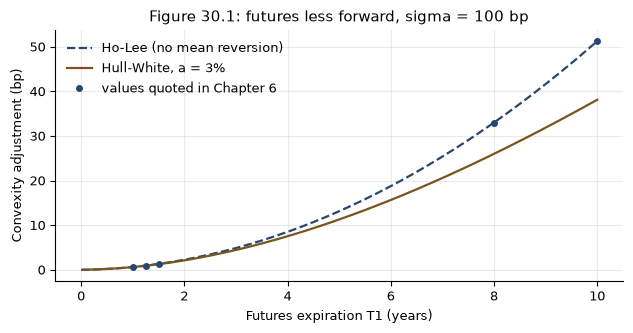

In [3]:
SIG_N = 0.01                                   # 100 bp a year, absolute


def ho_lee(T1, T2, sigma=SIG_N):
    """Eq. (30.12): futures rate less forward rate."""
    return 0.5 * sigma ** 2 * T1 * T2


def hull_white(T1, T2, sigma=SIG_N, a=0.03):
    """Eq. (30.13)."""
    B = lambda t1, t2: (1 - np.exp(-a * (t2 - t1))) / a
    tau = T2 - T1
    return B(T1, T2) * (B(T1, T2) * (1 - np.exp(-2 * a * T1)) + 2 * a * B(0, T1) ** 2) \
        * sigma ** 2 / (4 * a * tau)


for T1, printed in ((1.0, 0.625), (1.25, 0.9375), (1.5, 1.3125), (8.0, 33.0), (10.0, 51.25)):
    show("Ho-Lee at T1 = %5.2f, bp" % T1, 1e4 * ho_lee(T1, T1 + 0.25), printed, 1e-9)
for a in (1e-4, 1e-6):
    show("Hull-White at a = %.0e, 5y, bp (Ho-Lee 13.125)" % a,
         1e4 * hull_white(5.0, 5.25, a=a), 13.125, 0.02)
ratio = hull_white(10.0, 10.25) / ho_lee(10.0, 10.25)
show("ten years: Hull-White below Ho-Lee by, %", 100 * (1 - ratio), 25.0, 5.0)
show("20% used as a normal vol: times too large", (0.20 / SIG_N) ** 2, 400.0, 1e-9)
show("simple-rate correction at one year, bp", 1e4 * 0.5 * SIG_N ** 2 * 0.25 * 1.0, 0.1, 0.03)

# The table beside Figure 30.1: both models at selected expirations, to two decimals.
TABLE = ((1, 0.63, 0.60), (2, 2.25, 2.11), (3, 4.88, 4.44),
         (5, 13.13, 11.27), (8, 33.00, 25.99), (10, 51.25, 38.11))
for T1, hl_p, hw_p in TABLE:
    show("table, Ho-Lee at T1 = %2d, bp" % T1, 1e4 * ho_lee(T1, T1 + 0.25), hl_p, 0.0051)
    show("table, Hull-White at T1 = %2d, bp" % T1, 1e4 * hull_white(T1, T1 + 0.25), hw_p, 0.0051)

T = np.linspace(0, 10, 201)
fig, ax = plt.subplots()
ax.plot(T, 1e4 * ho_lee(T, T + 0.25), "--", color=BLUE, lw=1.6, label="Ho-Lee (no mean reversion)")
ax.plot(T[1:], 1e4 * hull_white(T[1:], T[1:] + 0.25), "-", color=AMBER, lw=1.6,
        label="Hull-White, a = 3%")
ax.plot([1, 1.25, 1.5, 8, 10], [0.625, 0.9375, 1.3125, 33.0, 51.25], "o", color=BLUE, ms=4,
        label="values quoted in Chapter 6")
ax.set_xlabel("Futures expiration T1 (years)"); ax.set_ylabel("Convexity adjustment (bp)")
ax.set_title("Figure 30.1: futures less forward, sigma = 100 bp")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. In-arrears convexity — Example 30.2

Paying a rate at the start of its period instead of the end changes the measure from $Q^{T_2}$ to
$Q^{T_1}$, and the density between them is affine in the rate, so the adjustment is exact:
$\tau\,\mathrm{Var}(R)/(1+F\tau)$. It is positive, because the payment is accelerated rather than
deferred, and receiving a high rate early is worth more.

The usual first-order form replaces $e^{\sigma^2T_1}-1$ by $\sigma^2T_1$ and understates the
adjustment by 15% here. The plot shows that the shortfall is a function of $\sigma^2T_1$ alone, which
is why it matters for long-dated or high-volatility rates and not otherwise.

variance                                           0.000587   book    0.000587   ok
exact adjustment, bp                               1.452824   book    1.450000   ok
rate to use, %                                     4.014528   book    4.014500   ok
first-order adjustment, bp                         1.237624   book    1.240000   ok
error of the first-order form, %                  14.812519   book   15.000000   ok
E^{T2}[R Lambda] by quadrature, %                  4.014528   book    4.014500   ok


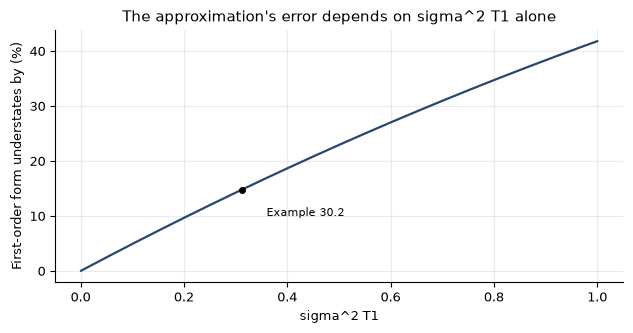

In [4]:
F, SIG_IA, T1_IA, TAU_IA = 0.04, 0.25, 5.0, 0.25

var = F ** 2 * (exp(SIG_IA ** 2 * T1_IA) - 1)           # lognormal variance
exact = TAU_IA * var / (1 + F * TAU_IA)                 # eq. (30.14)
first = F ** 2 * SIG_IA ** 2 * T1_IA * TAU_IA / (1 + F * TAU_IA)
show("variance", var, 5.8694e-4, 5e-8)
show("exact adjustment, bp", 1e4 * exact, 1.45, 5e-3)
show("rate to use, %", 100 * (F + exact), 4.0145, 5e-5)
show("first-order adjustment, bp", 1e4 * first, 1.24, 5e-3)
show("error of the first-order form, %", 100 * (exact - first) / exact, 15.0, 0.6)

# the same expectation done directly, E^{T2}[R Lambda], with Lambda = (1 + R tau)/(1 + F tau)
direct = lognormal_expect(lambda r: r * (1 + r * TAU_IA) / (1 + F * TAU_IA), F, SIG_IA * sqrt(T1_IA))
show("E^{T2}[R Lambda] by quadrature, %", 100 * direct, 4.0145, 5e-5)

x = np.linspace(0.001, 1.0, 200)                        # sigma^2 T1
fig, ax = plt.subplots()
ax.plot(x, 100 * (np.exp(x) - 1 - x) / (np.exp(x) - 1), "-", color=BLUE, lw=1.6)
ax.plot([SIG_IA ** 2 * T1_IA], [100 * (exact - first) / exact], "o", color="black", ms=4)
ax.annotate("Example 30.2", xy=(SIG_IA ** 2 * T1_IA, 100 * (exact - first) / exact),
            xytext=(0.36, 10), fontsize=8)
ax.set_xlabel("sigma^2 T1"); ax.set_ylabel("First-order form understates by (%)")
ax.set_title("The approximation's error depends on sigma^2 T1 alone")
plt.tight_layout(); plt.show()

## 4. The CMS adjustment — Example 30.3 and Figure 30.2

A CMS coupon is a single payment of a swap rate, and the swap rate is unbiased only under the annuity
measure. What is pinned down is the bond price $G$, whose forward price is a martingale under
$Q^{T_1}$, and it is convex in the rate, so by Jensen's
inequality the rate's distribution has to sit higher than the forward to keep $E^{T_1}[G] = G(S_0)$. The
first plot is Figure 30.2's geometry, from the same constants the chapter's TikZ uses.

Example 30.3's 9.0 basis points comes from a second-order expansion. The second cell checks it
against the full calculation under the annuity measure: take the swap rate lognormal there, write the
annuity as the flat-yield annuity of the rate, and change measure by the integral
$E^{T_1}[S] = E^{A}[S/A(S)]\,/\,E^{A}[1/A(S)]$. That gives 10.1 basis points against the expansion's
9.0. Most of the difference is the substitution Section 3 measured: the expansion uses $\sigma^2T_1$
where the lognormal variance has $e^{\sigma^2T_1}-1$, and correcting only that brings it to 9.95. The
rest is the higher-order curvature of the annuity. The gap is small where the adjustment is small and
grows quickly with tenor and time to reset, which is the practical case for the chapter's advice:
price by replication, and keep the formula as a quick estimate and a check.

The last plot is the chapter's warning that the adjustment is not a refinement: on long-tenor rates
reset far out it passes 50 basis points.

G(2)                                               1.750673   book    1.750673   ok
G(6)                                               0.571209   book    0.571209   ok
chord midpoint at S0                               1.160941   book    1.160941   ok
shifted mean E[S]                                  4.532967   book    4.533000   ok
G at the shifted mean                              0.861370   book    0.861370   ok
average of G after the shift                       1.000000   book    1.000000   ok


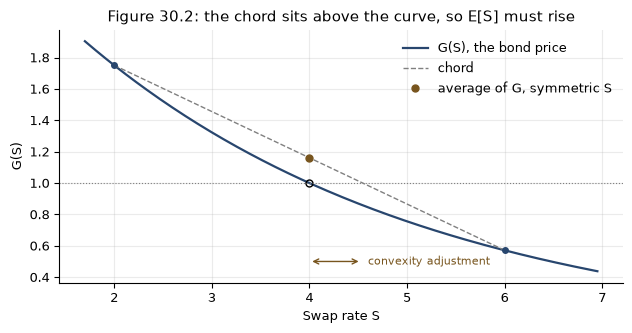

In [5]:
# Figure 30.2: G(S) = exp(-0.28 (S - 4)), outcomes at S0 -/+ 2, curvature exaggerated
G = lambda s: np.exp(-0.28 * (s - 4.0))
shift = log(np.cosh(0.56)) / 0.28                       # where the average of G is back at G(S0)
show("G(2)", G(2.0), 1.750673, 5e-7)
show("G(6)", G(6.0), 0.571209, 5e-7)
show("chord midpoint at S0", 0.5 * (G(2.0) + G(6.0)), 1.160941, 5e-7)
show("shifted mean E[S]", 4.0 + shift, 4.5330, 5e-5)
show("G at the shifted mean", G(4.0 + shift), 0.861370, 5e-7)
show("average of G after the shift", 0.5 * (G(2.0 + shift) + G(6.0 + shift)), 1.0, 1e-12)

s = np.linspace(1.7, 6.95, 200)
fig, ax = plt.subplots()
ax.plot(s, G(s), "-", color=BLUE, lw=1.6, label="G(S), the bond price")
ax.plot([2, 6], [G(2.0), G(6.0)], "--", color="gray", lw=1.0, label="chord")
ax.plot([2, 6], [G(2.0), G(6.0)], "o", color=BLUE, ms=4)
ax.plot([4], [0.5 * (G(2.0) + G(6.0))], "o", color=AMBER, ms=5, label="average of G, symmetric S")
ax.plot([4], [1.0], "o", mfc="none", color="black", ms=5)
ax.axhline(1.0, color="gray", ls=":", lw=0.8)
ax.annotate("", xy=(4 + shift, 0.5), xytext=(4, 0.5), arrowprops=dict(arrowstyle="<->", color=AMBER))
ax.text(4.6, 0.48, "convexity adjustment", color=AMBER, fontsize=8)
ax.set_xlabel("Swap rate S"); ax.set_ylabel("G(S)")
ax.set_title("Figure 30.2: the chord sits above the curve, so E[S] must rise")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

G'(0.04)                                          -4.451822   book   -4.451800   ok
  equals minus the annuity, eq. (30.17)           -4.451822   book   -4.451800   ok
G''(0.04)                                         25.012485   book   25.012500   ok
G''/G'                                            -5.618482   book   -5.618500   ok
CMS rate, %                                        4.089896   book    4.090000   ok
convexity adjustment, bp                           8.989572   book    9.000000   ok

formula against the annuity-measure integral (quadrature), adjustment in bp
   tenor     T1    (30.16)     exact variance   integral
      5y     5y       8.99               9.95      10.11
     10y     5y      15.93              17.63      18.18
     10y    10y      31.86              39.17      41.87
     10y    20y      63.72              97.61     112.91
     30y    20y     155.41             238.08     275.36


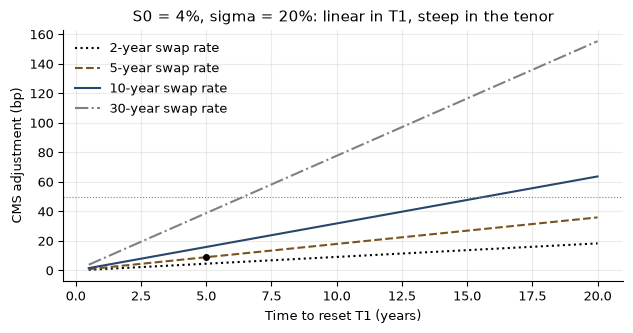

In [6]:
def annuity(y, n):
    """Eq. (30.17): the flat-yield annuity of an n-year annual swap."""
    return (1 - (1 + y) ** -n) / y


def g_derivs(S0, n):
    """G'(S0) and G''(S0) for an n-year annual bond with coupon S0, priced at yield S0."""
    i = np.arange(1, n + 1)
    c = np.full(n, S0); c[-1] += 1.0
    return float(np.sum(-i * c * (1 + S0) ** (-i - 1))), float(np.sum(i * (i + 1) * c * (1 + S0) ** (-i - 2)))


def cms_formula(S0, sig, T1, n):
    """Eq. (30.16)."""
    g1, g2 = g_derivs(S0, n)
    return S0 - 0.5 * S0 ** 2 * sig ** 2 * T1 * g2 / g1


def cms_integral(S0, sig, T1, n):
    """E^{T1}[S] = E^A[S / A(S)] / E^A[1 / A(S)], S lognormal under the annuity measure."""
    tv = sig * sqrt(T1)
    return (lognormal_expect(lambda x: x / annuity(x, n), S0, tv)
            / lognormal_expect(lambda x: 1 / annuity(x, n), S0, tv))


S0, SIG, T1, NY = 0.04, 0.20, 5.0, 5
g1, g2 = g_derivs(S0, NY)
show("G'(0.04)", g1, -4.4518, 5e-5)
show("  equals minus the annuity, eq. (30.17)", -annuity(S0, NY), -4.4518, 5e-5)
show("G''(0.04)", g2, 25.0125, 5e-5)
show("G''/G'", g2 / g1, -5.6185, 5e-5)
show("CMS rate, %", 100 * cms_formula(S0, SIG, T1, NY), 4.090, 5e-4)
show("convexity adjustment, bp", 1e4 * (cms_formula(S0, SIG, T1, NY) - S0), 9.0, 0.05)
print()
print("formula against the annuity-measure integral (quadrature), adjustment in bp")
print("%8s %6s %10s %18s %10s" % ("tenor", "T1", "(30.16)", "exact variance", "integral"))
for n, t1 in ((5, 5.0), (10, 5.0), (10, 10.0), (10, 20.0), (30, 20.0)):
    f_ = 1e4 * (cms_formula(S0, SIG, t1, n) - S0)
    x = SIG ** 2 * t1
    i_ = 1e4 * (cms_integral(S0, SIG, t1, n) - S0)
    print("%7dy %5.0fy %10.2f %18.2f %10.2f" % (n, t1, f_, f_ * (exp(x) - 1) / x, i_))

t1s = np.linspace(0.5, 20, 60)
fig, ax = plt.subplots()
for n, ls, col in ((2, ":", "black"), (5, "--", AMBER), (10, "-", BLUE), (30, "-.", "gray")):
    ax.plot(t1s, [1e4 * (cms_formula(S0, SIG, t, n) - S0) for t in t1s], ls, color=col, lw=1.5,
            label="%d-year swap rate" % n)
ax.axhline(50, color="gray", lw=0.8, ls=":")
ax.plot([T1], [1e4 * (cms_formula(S0, SIG, T1, NY) - S0)], "o", color="black", ms=4)
ax.set_xlabel("Time to reset T1 (years)"); ax.set_ylabel("CMS adjustment (bp)")
ax.set_title("S0 = 4%, sigma = 20%: linear in T1, steep in the tenor")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. A CMS spread coupon — Example 30.4

A spread between two swap rates looks as if its adjustments should cancel, and they do not: the ratio
$-G''/G'$ that drives each one is 3.4 times larger for a ten-year swap than for a two-year one. The
short leg's higher volatility works the other way and does not come close to overcoming it. The net
effect, +9.2 basis points, is 18% of the spread being valued, and it always widens the fair spread on
a steepener, so a dealer who left it out would underprice every note, consistently.

In [7]:
LEGS = (("2-year", 0.0390, 0.24, 2, 1.8888, 5.4189, 2.8690, 6.28, 3.9628),
        ("10-year", 0.0440, 0.18, 10, 7.9518, 78.3883, 9.8580, 15.46, 4.5546))
adjusted = {}
for name, s0, sig, n, ann_p, g2_p, ratio_p, adj_p, rate_p in LEGS:
    g1, g2 = g_derivs(s0, n)
    adjusted[name] = cms_formula(s0, sig, 5.0, n)
    show("%s leg: annuity A = -G'" % name, -g1, ann_p, 5e-5)
    show("%s leg: G''" % name, g2, g2_p, 5e-5)
    show("%s leg: -G''/G'" % name, -g2 / g1, ratio_p, 5e-5)
    show("%s leg: adjustment, bp" % name, 1e4 * (adjusted[name] - s0), adj_p, 0.01)
    show("%s leg: adjusted rate, %%" % name, 100 * adjusted[name], rate_p, 5e-5)
spread = adjusted["10-year"] - adjusted["2-year"]
show("adjusted spread, bp", 1e4 * spread, 59.18, 0.02)
show("net convexity effect, bp", 1e4 * spread - 50.0, 9.2, 0.05)
show("as a share of the spread, %", 100 * (1e4 * spread - 50.0) / 50.0, 18.0, 0.5)
show("ratio of -G''/G', ten-year to two-year", 9.8580 / 2.8690, 3.4, 0.05)

2-year leg: annuity A = -G'                        1.888801   book    1.888800   ok
2-year leg: G''                                    5.418936   book    5.418900   ok
2-year leg: -G''/G'                                2.868983   book    2.869000   ok
2-year leg: adjustment, bp                         6.283761   book    6.280000   ok
2-year leg: adjusted rate, %                       3.962838   book    3.962800   ok
10-year leg: annuity A = -G'                       7.951768   book    7.951800   ok
10-year leg: G''                                  78.388328   book   78.388300   ok
10-year leg: -G''/G'                               9.857975   book    9.858000   ok
10-year leg: adjustment, bp                       15.458882   book   15.460000   ok
10-year leg: adjusted rate, %                      4.554589   book    4.554600   ok
adjusted spread, bp                               59.175122   book   59.180000   ok
net convexity effect, bp                           9.175122   book    9.2000

## 6. The quanto drift — the Nikkei forward

A quanto pays a foreign variable in domestic currency at a fixed rate, and its dealer hedges with the
foreign asset, whose gains arrive in foreign currency. Under the domestic measure the asset's drift is
$r_f - \rho\sigma_V\sigma_S$, with $S$ in domestic currency per foreign unit, so the quanto forward is
the foreign forward times $e^{-\rho\sigma_V\sigma_S T}$.

For a dollar-settled Nikkei forward, $\rho < 0$ (Japanese equities have tended to rise as the yen
weakens), and at $\rho = -0.3$, $\sigma_V = 20\%$, $\sigma_S = 10\%$ the one-year quanto forward sits
about 0.6% above the index's ordinary forward in yen. The plot shows why the chapter calls this correlation risk: across
the range the Nikkei–yen correlation has visited, the adjustment changes sign.

Nikkei quanto premium, one year, %                 0.601804   book    0.600000   ok
no correlation, no adjustment                      1.000000   book    1.000000   ok


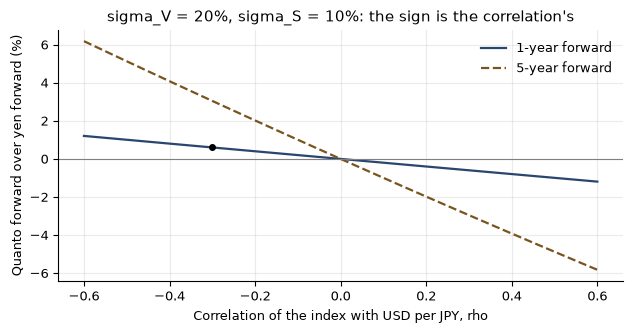

In [8]:
def quanto_factor(rho, sig_v, sig_s, T):
    """Eq. (30.20): quanto forward over the foreign-currency forward."""
    return np.exp(-rho * sig_v * sig_s * T)


show("Nikkei quanto premium, one year, %", 100 * (quanto_factor(-0.3, 0.20, 0.10, 1.0) - 1), 0.6, 0.05)
show("no correlation, no adjustment", quanto_factor(0.0, 0.20, 0.10, 1.0), 1.0, 1e-12)

rhos = np.linspace(-0.6, 0.6, 121)
fig, ax = plt.subplots()
for T, ls, col in ((1.0, "-", BLUE), (5.0, "--", AMBER)):
    ax.plot(rhos, 100 * (quanto_factor(rhos, 0.20, 0.10, T) - 1), ls, color=col, lw=1.6,
            label="%.0f-year forward" % T)
ax.axhline(0, color="gray", lw=0.8)
ax.plot([-0.3], [100 * (quanto_factor(-0.3, 0.20, 0.10, 1.0) - 1)], "o", color="black", ms=4)
ax.set_xlabel("Correlation of the index with USD per JPY, rho")
ax.set_ylabel("Quanto forward over yen forward (%)")
ax.set_title("sigma_V = 20%, sigma_S = 10%: the sign is the correlation's")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## What reproduced, and what to take from it

If the cell below reports that every figure reproduces, the notebook matches the chapter.

Two habits are worth carrying out of here. **Ask which measure the number is unbiased under**:
every adjustment above is the answer to that one question, asked of a different payoff. And **check
an approximation against the calculation it approximates** whenever the calculation is one integral
away: the timing formula's cost, the in-arrears first-order error and the CMS expansion's gap were
each found that way, and the last of them is why desks replicate rather than expand.

In [9]:
if BAD:
    print("%d figure(s) differ from the chapter:" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("every figure in this notebook reproduces the chapter")

every figure in this notebook reproduces the chapter
